In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

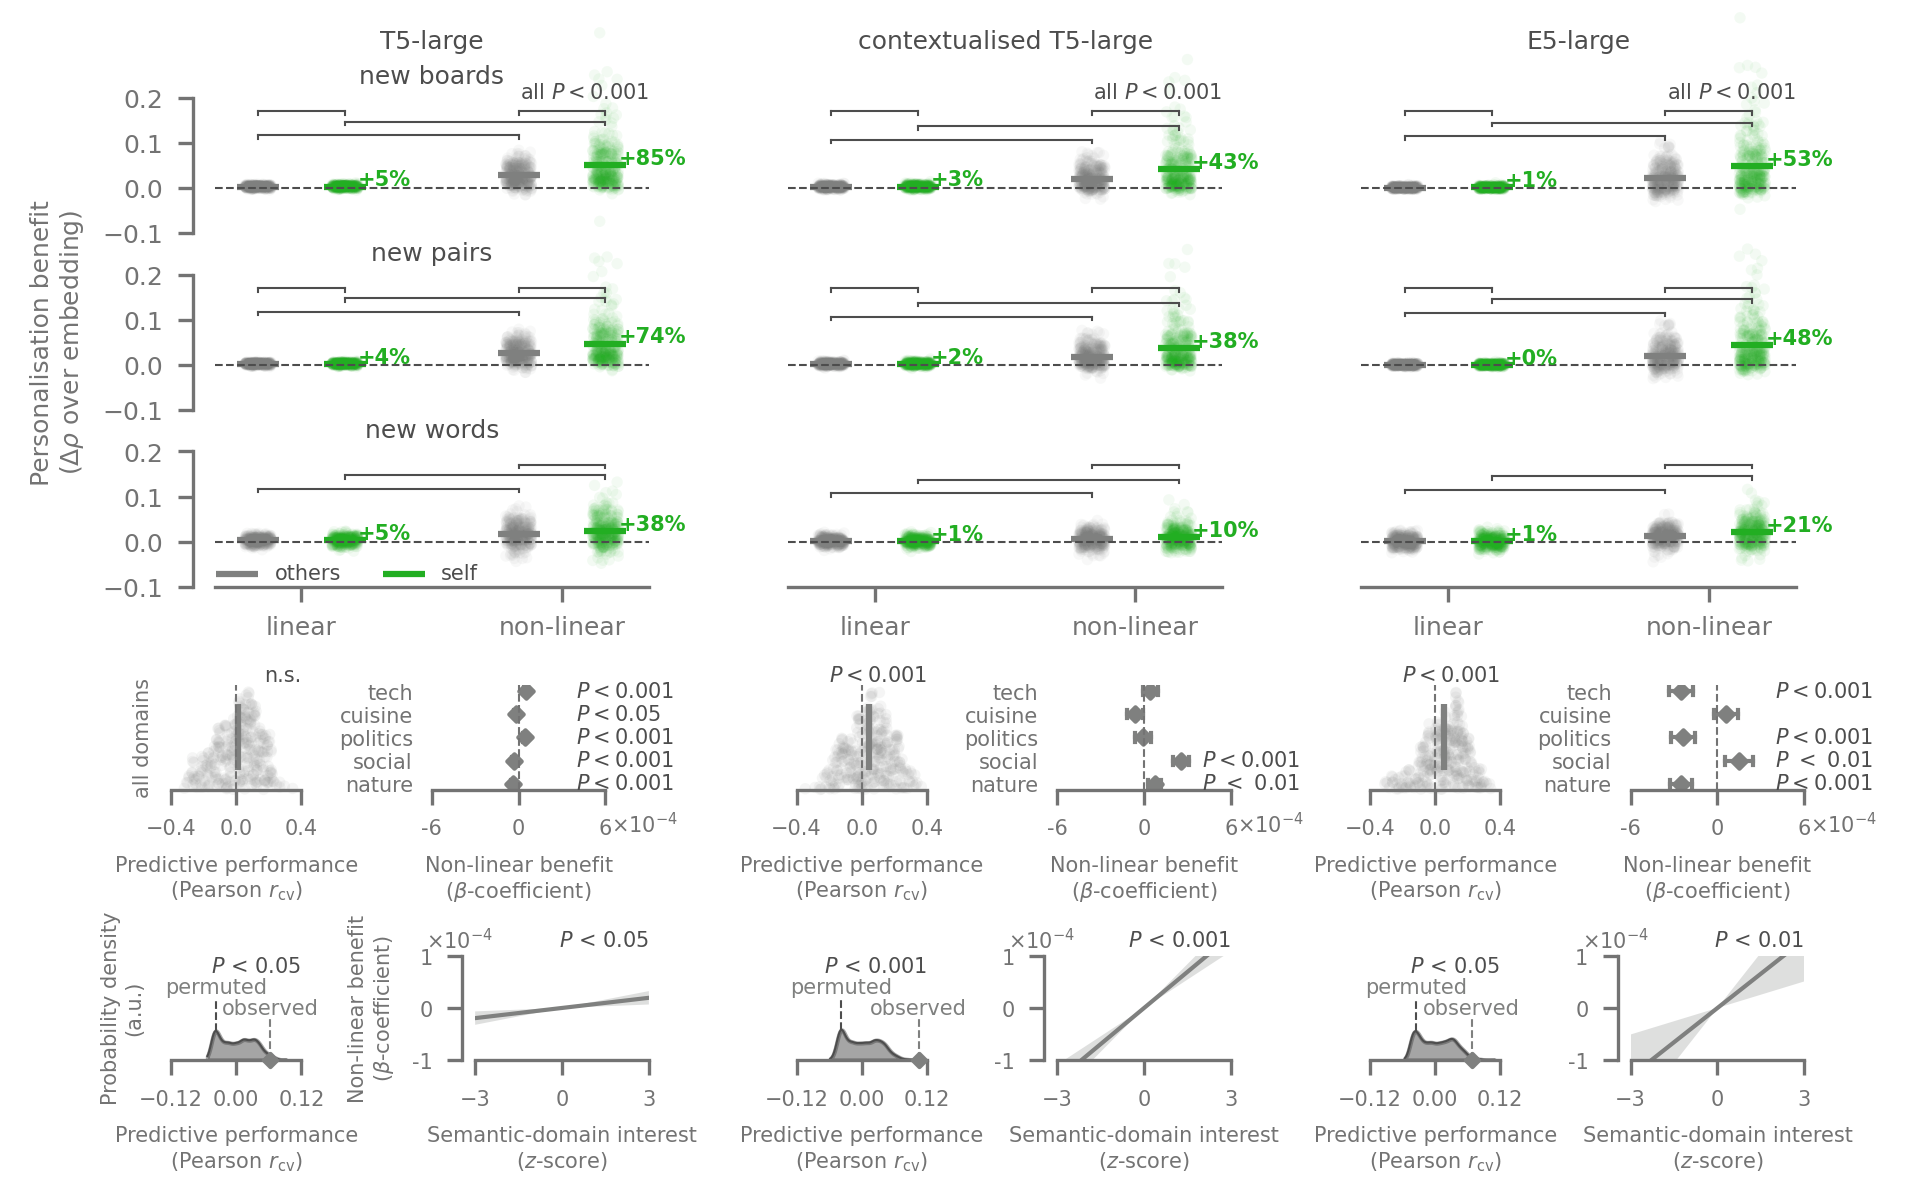

In [107]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

exp = 2
run = 6
emb = 'glove'
compute_stat = True

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

models = ['linear', 'nonlinear']
models_labels = ['linear', 'non-linear']

prefixes = ['', 'pns_', 'uns_']
prefixes_labels = ['new boards', 'new pairs', 'new words']

fig, ax = plt.subplots(figsize = (6.40, 4.0), dpi = 300)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

for e_i, emb in enumerate(mods):
    #"""
    '''
    panel A
    '''
    ax0 = ax.inset_axes([0.065 + 0.33 * e_i, 0.820, 0.25, 0.13])
    ax1 = ax.inset_axes([0.065 + 0.33 * e_i, 0.650, 0.25, 0.13])
    ax2 = ax.inset_axes([0.065 + 0.33 * e_i, 0.480, 0.25, 0.13])

    axes1 = [ax0, ax1, ax2]

    X_jitter = np.random.uniform(-0.15, 0.15, size = (303,))
    offset = 0
    sig_off = 0.0075
    sig_base = 0.17

    R_sh = np.zeros((len(prefixes), len(models), 303))
    R_in = np.zeros_like(R_sh)

    min_p = 0.0

    for m_i, mod in enumerate(models):
        R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{emb}_mod-{mod}.pt', map_location=torch.device('cpu'))

        for p_i, pre in enumerate(prefixes):
            R_base = R[f'{pre}rho_BE'].squeeze().cpu().numpy().diagonal()
            R_indiv = R[f'{pre}rho_BZ'].cpu().numpy().diagonal().squeeze()
            R_group = R[f'{pre}rho_BZ'].cpu().numpy()
            R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)
            R_noise = R['rho_nc'].cpu().numpy().squeeze()

            R_a = np.array([R_base, R_group, R_indiv])
            R_d = R_a[1:] - R_a[0]

            R_sh[p_i,m_i,:] = R_d[0,:]
            R_in[p_i,m_i,:] = R_d[1,:]

            if compute_stat:
                design = [(1, 0), (2, 1), (2, 0)]
                group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
                pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

                model.stats.save_results(group, f'./deliverable/csv/suppfig6/{emb}_a_{mod}_{pre}_group.csv')
                model.stats.save_results(pairwise, f'./deliverable/csv/suppfig6/{emb}_a_{mod}_{pre}_pairs.csv')

            for i, R_i in enumerate(R_d):
                mu = R_i.mean()
                se = model.stats.bootstrap_se(R_i)
                x_i = 3 * m_i + i + X_jitter
                x_j = 3 * m_i + i

                if offset < (mu + 1.96 * se):
                    offset = mu + 1.96 * se

                label = None
                if (p_i == (len(prefixes) - 1)) and (i == 0) and (m_i == 0):
                    label = 'others'
                elif (p_i == (len(prefixes) - 1)) and (i == 1) and (m_i == 0):
                    label = 'self'

                axes1[p_i].scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i+1], s = 30, alpha = 0.05, clip_on = False)
                axes1[p_i].scatter([x_j], [mu], color = cols[i+1], marker = '_', s = 100, clip_on = False, zorder = 2, label = label)

                if i == 1:
                    pct = round(pairwise[-1]['pct_mu'])
                    axes1[p_i].annotate(
                        fr'+{pct}%',
                        xy = (0, 0),
                        xytext = (x_j + 0.15, mu + 0.015),
                        ha = 'left',
                        va = 'center',
                        fontsize = 5,
                        fontweight = 'bold',
                        color = cols[i + 1],
                        annotation_clip = False
                    )

                if i == 0 and False:
                    pct = round(pairwise[0]['pct_mu'])
                    axes1[p_i].annotate(
                        fr'+{pct}%',
                        xy = (0, 0),
                        xytext = (x_j + 0.15, mu + 0.015),
                        ha = 'left',
                        va = 'center',
                        fontsize = 5,
                        fontweight = 'bold',
                        color = cols[i + 1],
                        annotation_clip = False
                    )

            if pairwise[1]['p_cor'] <= 0.05:
                if pairwise[1]['p_cor'] > min_p:
                    min_p = pairwise[1]['p_cor']

                x_i = 3 * m_i

                axes1[p_i].plot(
                    [x_i, x_i + 1],
                    [sig_base, sig_base],
                    color = plots.colours.H2,
                    lw = 0.5,
                    clip_on = False
                )

                axes1[p_i].plot(
                    [x_i, x_i],
                    [sig_base - sig_off, sig_base],
                    color = plots.colours.H2,
                    lw = 0.5,
                    clip_on = False
                )

                axes1[p_i].plot(
                    [x_i + 1, x_i + 1],
                    [sig_base - sig_off, sig_base],
                    color = plots.colours.H2,
                    lw = 0.5,
                    clip_on = False
                )

    sig_off1 = 0.06
    sig_off2 = 0.09

    for i in range(len(prefixes)):
        design = [(1, 0)]

        if compute_stat:
            pairwise = model.stats.pairwise_tests(
                R_sh[i,:,:], 
                design, 
                test = hypothesis_test, 
                alternative = hypothesis_alternative, 
                method = hypothesis_method, 
                se = hypothesis_se
            )

            model.stats.save_results(pairwise, f'./deliverable/csv/suppfig6/{emb}_a_sh{i}_pairs.csv')

        if pairwise[0]['p_cor'] < 0.05:
            x_i = 0
            p_i = i

            if pairwise[0]['p_cor'] > min_p:
                min_p = pairwise[0]['p_cor']

            axes1[p_i].plot(
                [x_i, x_i + 3],
                [offset + sig_off1, offset + sig_off1],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

            axes1[p_i].plot(
                [x_i, x_i],
                [offset + sig_off1 - sig_off, offset + sig_off1],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

            axes1[p_i].plot(
                [x_i + 3, x_i + 3],
                [offset + sig_off1 - sig_off, offset + sig_off1],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

        if compute_stat:
            pairwise = model.stats.pairwise_tests(
                R_in[i,:,:], 
                design, 
                test = hypothesis_test, 
                alternative = hypothesis_alternative, 
                method = hypothesis_method, 
                se = hypothesis_se
            )

            model.stats.save_results(pairwise, f'./deliverable/csv/suppfig6/{emb}_a_in{i}_pairs.csv')

        if pairwise[0]['p_cor'] < 0.05:
            x_i = 1
            p_i = i

            if pairwise[0]['p_cor'] > min_p:
                min_p = pairwise[0]['p_cor']

            axes1[p_i].plot(
                [x_i, x_i + 3],
                [offset + sig_off2, offset + sig_off2],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

            axes1[p_i].plot(
                [x_i, x_i],
                [offset + sig_off2 - sig_off, offset + sig_off2],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

            axes1[p_i].plot(
                [x_i + 3, x_i + 3],
                [offset + sig_off2 - sig_off, offset + sig_off2],
                color = plots.colours.H2,
                lw = 0.5,
                clip_on = False
            )

    for i in range(len(prefixes)):
        axes1[i].plot([-0.5, 3 * len(models) - 1.5], [0, 0], lw = 0.5, ls = '--', color = plots.colours.H2)
        axes1[i].set_xlim([-0.5, 3 * len(models) - 1.5])
        axes1[i].set_xticks(np.arange(0.5, 3 * len(models), 3.0))
        if i == len(prefixes) - 1:
            axes1[i].set_xticklabels(models_labels)
        else:
            axes1[i].set_xticks([])
            axes1[i].set_xticklabels([])

        axes1[i].set_ylim([-0.1, 0.2])
        axes1[i].set_yticks([-0.1, 0.0, 0.1, 0.2])
        if (e_i == 0) and (i == 1):
            axes1[i].set_ylabel('Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)', )
        axes1[i].spines['left'].set_position(('axes', -0.05))
        
        sns.despine(ax = axes1[i])

        if i != len(prefixes) - 1:
            axes1[i].spines['bottom'].set_visible(False)

        if e_i == 0:
            axes1[i].annotate(
                prefixes_labels[i],
                xy = (0, 0),
                xytext = (2.0, 0.22),
                ha = 'center',
                va = 'bottom',
                fontsize = 6,
                color = plots.colours.H2,
                annotation_clip = False
            )
        
        if e_i > 0:
            axes1[i].set_yticks([])
            axes1[i].spines['left'].set_visible(False)
            axes1[i].tick_params(axis = 'y', which = 'both', length = 0)
        
        axes1[i].yaxis.label.set_color(plots.colours.H3)
        axes1[i].xaxis.label.set_color(plots.colours.H3)
        axes1[i].tick_params(axis = 'x', colors = plots.colours.H3)
        axes1[i].tick_params(axis = 'y', colors = plots.colours.H3)
        axes1[i].spines['bottom'].set_color(plots.colours.H3)
        axes1[i].spines['left'].set_color(plots.colours.H3)

    sigstr = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05' if min_p <= 0.05 else 'n.s.'
    axes1[0].annotate(
        fr'all {sigstr}',
        xy = (0, 0),
        xytext = (4.5, 0.19),
        ha = 'right',
        va = 'bottom',
        fontsize = 5,
        color = plots.colours.H2,
        annotation_clip = False
    )

    if e_i == 0:
        axes1[-1].legend(
            bbox_to_anchor = (0.65, 0.31),
            frameon = False,
            ncols = 2,
            fontsize = 5,
            labelcolor = plots.colours.H2
        )
    #"""
    
    '''
    panel B
    '''
    outputs = torch.load(
        f'../data/ds-exp2/derivatives/run-00{run}/tasks/task-maspace_bse0-{emb}_mod-delta.pt', 
        map_location = torch.device('cpu'),
        weights_only = False
    )
    
    fct = 0.0 if e_i == 0 else 0.36 if e_i == 1 else 0.69
    ax4 = ax.inset_axes([0.040 + fct, 0.285, 0.075, 0.10])
    ax6 = ax.inset_axes([0.190 + fct, 0.285, 0.100, 0.10])

    # left panel
    perf = outputs['S1_r_full'][emb].mean(1)
    mu = perf.mean()
    if compute_stat:
        stat_p = model.stats.sample_tests(perf[None,:], popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
        model.stats.save_results(stat_p, f'./deliverable/csv/suppfig6/{emb}_b_group.csv')
    min_p = stat_p[0]['p_cor']
    sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'
    
    from sklearn.neighbors import KernelDensity
    perm_pad = 0.0
    kde = KernelDensity(bandwidth = 0.01).fit(perf[:,None])
    scores = kde.score_samples(perf[:,None])
    scores = np.exp(scores)
    scores = np.abs(scores / np.trapezoid(scores, perf))
    scores = scores / scores.max()
    scores = 0.50 * scores - 0.25
    x_i = np.array([
        np.random.uniform(low = -0.25, high = scores[i])
        for i in range(len(scores))
    ])
    ax4.scatter(perf, x_i, marker = '.', edgecolor = 'None', facecolor = cols[1], s = 30, alpha = 0.075, clip_on = False)

    ax4.scatter([mu], [0], color = cols[1], marker = '|', s = 250, clip_on = False, zorder = 2)
    ax4.plot([0, 0], [-0.25, 0.25], color = plots.colours.H3, lw = 0.5, ls = '--')
    ax4.annotate(
        sig,
        xy = (0, 0),
        xytext = (0.40, 0.25),
        ha = 'right',
        va = 'bottom',
        fontsize = 5,
        color = plots.colours.H2
    )

    ax4.set_ylim([-0.25, 0.25])
    ax4.set_yticks([])
    ax4.set_xlim([-0.4, 0.4])
    ax4.set_xticks([-0.4, 0.0, 0.4])
    ax4.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{\text{{cv}}}}$)')
    ax4.xaxis.label.set_fontsize(5)
    
    sns.despine(ax = ax4)
    ax4.spines['left'].set_position(('axes', -0.075))
    ax4.spines['left'].set_visible(False)
    ax4.tick_params(axis = 'y', which = 'both', length = 0)

    if e_i == 0:
        ax4.annotate(
            'all domains',
            xy = (0, 0),
            xytext = (-0.575, 0.0),
            fontsize = 5,
            color = plots.colours.H3,
            rotation = 90,
            ha = 'center',
            va = 'center'
        )

    # right panel
    redu = (perf[:,None] - outputs['S1_r_redu'][emb].mean(2)).mT
    mu = redu.mean(1)
    se = model.stats.bootstrap_se(redu.mT)
    if compute_stat:
        stat_r = model.stats.sample_tests(redu, popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
        model.stats.save_results(stat_r, f'./deliverable/csv/suppfig6/{emb}_b_redu.csv')
    coef = outputs['S1_ß_full'][emb].mean(1).mT
    mu2 = coef.mean(1)
    se2 = model.stats.bootstrap_se(coef.mT)
    if compute_stat:
        stat_c = model.stats.sample_tests(coef, popmean = 0.0, test = 'sign', alternative = 'two-sided', method = 'holm', se = 'between')
        model.stats.save_results(stat_c, f'./deliverable/csv/suppfig6/{emb}_b_coef.csv')
    yoff = 0.175

    for i in range(redu.shape[0]):
        ax6.scatter([mu2[i]], [i], color = cols[1], marker = 'D', s = 6)
        ax6.plot([mu2[i] - 1.96 * se2[i], mu2[i] + 1.96 * se2[i]], [i, i], color = cols[1], lw = 1.0)
        ax6.plot([mu2[i] - 1.96 * se2[i], mu2[i] - 1.96 * se2[i]], [i - yoff, i + yoff], color = cols[1], lw = 1.0)
        ax6.plot([mu2[i] + 1.96 * se2[i], mu2[i] + 1.96 * se2[i]], [i - yoff, i + yoff], color = cols[1], lw = 1.0)
        min_p = stat_c[i]['p_cor']
        if min_p <= 0.05:
            sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P\ < \ 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

            ax6.annotate(
                sig,
                xy = (0, 0),
                xytext = (4.00e-4, i),
                ha = 'left',
                va = 'center',
                fontsize = 5,
                color = plots.colours.H2,
                annotation_clip = False
            )

    ax6.plot([0, 0], [-0.25, 4.25], color = plots.colours.H3, lw = 0.5, ls = '--')

    labels = ['nature', 'social', 'politics', 'cuisine', 'tech']
    ax6.set_yticks(np.arange(5), labels = labels)
    ax6.tick_params(axis = 'y', labelsize = 5)
    ax6.set_ylim([-0.25, 4.25])
    ax6.set_xlim([-6e-4, 6e-4])
    ax6.set_xticks([-6e-4, 0, 6e-4], labels = [-6, 0, 6])
    ax6.set_xlabel('Non-linear benefit\n' + fr'($\beta$-coefficient)')
    ax6.xaxis.label.set_fontsize(5)
    
    sns.despine(ax = ax6)
    ax6.spines['left'].set_position(('axes', -0.025))
    ax6.spines['left'].set_visible(False)
    ax6.tick_params(axis = 'y', which = 'both', length = 0)

    ax6.annotate(
        fr'$\times10^{{-4}}$',
        xy = (0, 0),
        xytext = (6.40e-4, -1.75),
        ha = 'left',
        va = 'center',
        fontsize = 5,
        color = plots.colours.H3
    )
    
    for ax_i in [ax4, ax6]:
        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.xaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3, labelsize = 5)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3, labelsize = 5)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)
    
    '''
    panel C
    '''
    
    perf = outputs['S2_r_full'][emb].mean()
    perm = outputs['S2_r_perm'][emb].mean((1, 2))
    diff = perf - perm
    coef = outputs['S2_ß_full'][emb].mean()
    poef = outputs['S2_ß_perm'][emb].mean((1, 2, 3))
    piff = coef - poef

    if compute_stat:
        stats_p2 = model.stats.sample_tests(diff[None,:], popmean = 0.0, test = 'permutation', alternative = 'greater', method = 'holm', se = 'between')
        stats_c2 = model.stats.sample_tests(piff[None,:], popmean = 0.0, test = 'permutation', alternative = 'two-sided', method = 'holm', se = 'between')
        model.stats.save_results(stats_p2, f'./deliverable/csv/suppfig6/{emb}_c_perm.csv')
        model.stats.save_results(stats_c2, f'./deliverable/csv/suppfig6/{emb}_c_coef.csv')
    
    fct = 0.0 if e_i == 0 else 0.360 if e_i == 1 else 0.690
    fct2 = 0.0 if e_i == 0 else -0.025
    ax7 = ax.inset_axes([0.040 + fct, 0.025, 0.075, 0.10])
    ax8 = ax.inset_axes([0.215 + fct + fct2, 0.025, 0.100, 0.10])
    
    # left side
    from sklearn.neighbors import KernelDensity
    perm_pad = 0.0
    kde = KernelDensity(bandwidth = 0.005).fit(perm[:,None])
    x_i = np.linspace(perm.min() - perm_pad, perm.max() + perm_pad, 100)
    scores = kde.score_samples(x_i[:,None])
    scores = np.exp(scores)
    scores = scores / np.trapezoid(scores, x_i)

    min_p = stats_p2[0]['p_cor']
    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

    indx = scores.argmax()
    xmax, ymax = x_i[indx], scores[indx]

    ax7.plot(x_i, scores, color = plots.colours.H2, linewidth = 0.5)
    ax7.fill_between(x_i, scores, color = plots.colours.H2, alpha = 0.5)
    ax7.plot([perf, perf], [0.0, 20.0], color = cols[1], linewidth = 0.5, linestyle = '--')
    ax7.scatter([perf], [0.0], marker = 'D', s = 5, color = cols[1], clip_on = False, zorder = 5)
    ax7.annotate('observed', xy = (0, 0), xytext = (perf, 20.0), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

    ax7.plot([xmax, xmax], [ymax, 30.0], zorder = 0, color = plots.colours.H2, linewidth = 0.5, linestyle = '--')
    ax7.annotate('permuted', xy = (0, 0), xytext = (xmax, 30.0), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

    ax7.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.12, 50.0), ha = 'right', va = 'top', color = plots.colours.H2, fontsize = 5)

    ax7.set_xlim([-0.12, 0.12])
    ax7.set_xticks([-0.12, 0.0, 0.12])
    ax7.set_ylim([0.0, 50.0])
    ax7.set_yticks([])
    ax7.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{\text{{cv}}}}$)')
    if e_i == 0: ax7.set_ylabel('Probability density\n(a.u.)')

    sns.despine(ax = ax7)
    ax7.spines['left'].set_position(('axes', -0.075))
    ax7.spines['left'].set_visible(False)
    ax7.tick_params(axis = 'y', which = 'both', length = 0)

    # right side
    coef = outputs['S2_ß_full'][emb].mean((0, 2, 3))
    mu = coef.mean()
    se = coef.std()#model.stats.bootstrap_se(coef)

    x = torch.linspace(-3, 3, 100, device = coef.device)
    y = mu * x
    y_lb = (mu - 1.96 * se) * x
    y_ub = (mu + 1.96 * se) * x

    ax8.fill_between(x, y_lb, y_ub, facecolor = cols[1], edgecolor = 'None', alpha = 0.25)
    ax8.plot(x, y, color = cols[1], lw = 1.0)

    min_p = stats_c2[0]['p_cor']
    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

    ax8.annotate(
        rep_p,
        xy = (0, 0),
        xytext = (3.0, 1.3e-4),
        ha = 'right',
        va = 'center',
        fontsize = 5,
        color = plots.colours.H2
    )

    ax8.set_ylim([-1e-4, 1e-4])
    ax8.set_yticks([-1e-4, 0.0, 1e-4], labels = ['-1', '0', '1'])
    if e_i == 0: ax8.set_ylabel('Non-linear benefit\n' + fr'($\beta$-coefficient)')
    ax8.set_xlim([-3.0, 3.0])
    ax8.set_xticks([-3.0, 0.0, 3.0])
    ax8.set_xlabel('Semantic-domain interest\n' + fr'($z$-score)')

    ax8.annotate(
        fr'$\times10^{{-4}}$',
        xy = (0, 0),
        xytext = (-3.53, 1.3e-4),
        ha = 'center',
        va = 'center',
        fontsize = 5,
        color = plots.colours.H3
    )

    sns.despine(ax = ax8)
    ax8.spines['left'].set_position(('axes', -0.075))
    
    for ax_i in [ax7, ax8]:
        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.xaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3, labelsize = 5)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3, labelsize = 5)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)
        ax_i.yaxis.label.set_fontsize(5)
        ax_i.xaxis.label.set_fontsize(5)
    
    ax0.annotate(
        mods_label[e_i],
        xy = (0, 0),
        xytext = (2.0, 0.325),
        ha = 'center',
        va = 'center',
        fontsize = 6,
        color = plots.colours.H2,
        annotation_clip = False
    )

'''
cosmetics
'''

fig.tight_layout()

ax.axis('off')

fig.savefig('./deliverable/png/suppfig6.png', dpi = 900)
fig.savefig('./deliverable/pdf/suppfig6.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig6.svg', dpi = 900, format = 'svg')